# 01｜宽基指数 ATR、网格策略与择时（研报第6—10页）

**使用顺序：从上到下，每次运行一个代码单元格。** 每个单元格只做一个小任务；运行后观察表格或图像，再继续下一格。

**本Notebook只读取指数数据，不使用ETF行情和分红数据。** 研报公式来自第6页，基础网格来自第7页表1，择时规则来自第9页表2。

**重要假设（与原研报结果不一定一致）：** ATR与择时窗口先设置为20日（N=20、N1=20），手续费默认0基点；第t日收盘才形成信号，第t+1日收盘调仓，新仓位从t+2日收盘收益起生效。研报演讲版没有披露全部实现参数。

## 第1章：准备数据

你已经下载了六只宽基指数。把这五份尚未包含在压缩包里的CSV放进 `data/raw/index/`。文件名里含指数六位代码即可，例如 `000300_tx_with_code.csv`。压缩包只附上你已上传的 `000688` 科创50示例，其余五只需要你自己放入。

In [32]:
# 1. 导入数据和画图工具
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

In [ ]:
# 2. 定义项目路径和回测假设
ROOT = Path.cwd().parent
INDEX_DIR = ROOT / 'data/raw/index'
OUTPUT = ROOT / 'outputs'
FEATURE_DIR = OUTPUT / 'features'
FEATURE_DIR.mkdir(parents=True, exist_ok=True)

END = pd.Timestamp('2025-09-30')
BASE_2019 = pd.Timestamp('2018-12-28')   # 2019年样本的净值基点
START_2019 = pd.Timestamp('2019-01-02')  # 2019年样本的首个收益日
BASE_2022 = pd.Timestamp('2021-12-31')   # 2022年样本的净值基点
START_2022 = pd.Timestamp('2022-01-04')  # 2022年样本的首个收益日

N, N1, FEE_BPS = 20, 60, 0.0 # 不考虑手续费
print('项目位置:', ROOT)

项目位置: d:\Project\Quant-ETF


In [34]:
# 3. 建立指数列表和名称
INDEX_NAMES = {
    '000016':'上证50', '000300':'沪深300', '000905':'中证500',
    '000852':'中证1000', '399006':'创业板指', '000688':'科创50'
}
print('本项目研究的指数:', INDEX_NAMES)

本项目研究的指数: {'000016': '上证50', '000300': '沪深300', '000905': '中证500', '000852': '中证1000', '399006': '创业板指', '000688': '科创50'}


In [35]:
# 4. 检查文件是否已经放进正确目录
for code, name in INDEX_NAMES.items():
    matches = list(INDEX_DIR.glob(f'*{code}_index*.csv'))
    print(f'{code} {name}:', [p.name for p in matches] or '未找到')

000016 上证50: ['000016_index.csv']
000300 沪深300: ['000300_index.csv']
000905 中证500: ['000905_index.csv']
000852 中证1000: ['000852_index.csv']
399006 创业板指: ['399006_index.csv']
000688 科创50: ['000688_index.csv']


In [36]:
# 5. 定义读取一只指数的函数
# 统一不同CSV的中英文列名，保留日期和OHLC

def read_index(file):
    d = pd.read_csv(file, encoding='utf-8-sig', dtype={'index_code':str})
    d = d.rename(columns={'日期':'date','开盘':'open','最高':'high','最低':'low','收盘':'close'})
    d['date'] = pd.to_datetime(d['date'])
    for key in ['open','high','low','close']:
        d[key] = pd.to_numeric(d[key], errors='raise')
    d = d.loc[d.date <= END].sort_values('date').set_index('date')
    assert d.index.is_unique and d[['open','high','low','close']].notna().all().all()
    return d

In [37]:
# 6. 将找到的所有指数CSV读到字典中
indexes = {}
for code in INDEX_NAMES:
    paths = list(INDEX_DIR.glob(f'*{code}_index*.csv'))
    if len(paths) == 1:
        indexes[code] = read_index(paths[0])
    elif len(paths) > 1:
        raise ValueError(f'指数{code}有多个文件，请保留一份')
print('已载入指数数量:', len(indexes))

已载入指数数量: 6


In [38]:
# 7. 查看每只指数的日期覆盖范围
coverage = pd.DataFrame([
    {'指数':INDEX_NAMES[c], '代码':c, '行数':len(d),
     '第一日':str(d.index.min().date()), '最后一日':str(d.index.max().date())}
    for c,d in indexes.items()
])
display(coverage)

,指数,代码,行数,第一日,最后一日
0,上证50,000016,5284,2004-01-02,2025-09-30
1,沪深300,000300,4980,2005-04-08,2025-09-30
2,中证500,000905,4551,2007-01-15,2025-09-30
3,中证1000,000852,2668,2014-10-17,2025-09-30
4,创业板指,399006,3725,2010-06-02,2025-09-30
5,科创50,000688,1395,2020-01-02,2025-09-30


## 第2章：复现第6页 ATR和NATR

这里先用一只指数逐列计算，理解公式后，再把同样的过程套到六只指数。

$$TR_t=\max(H_t-L_t,|H_t-C_{t-1}|,|L_t-C_{t-1}|)$$

$$ATR_t=MA(TR_t,N)；NATR_t=[C_t-MA(C_t,N)]/ATR_t$$

**请注意：研报的NATR不是技术分析软件常见的 ATR/Close × 100。**

In [39]:
# 8. 选择教学演示指数：优先沪深300，否则用已上传科创50
if not indexes:
    raise FileNotFoundError('data/raw/index/里没有指数CSV，请先放入文件')
DEMO_CODE = '000300' if '000300' in indexes else next(iter(indexes))
demo = indexes[DEMO_CODE].copy()
print('当前示例:', DEMO_CODE, INDEX_NAMES[DEMO_CODE]); display(demo[['high','low','close']].tail())

当前示例: 000300 沪深300


,high,low,close
date,,,
2025-09-24,4567.49,4494.11,4566.07
2025-09-25,4613.95,4558.84,4593.49
2025-09-26,4597.85,4550.05,4550.05
2025-09-29,4647.57,4541.43,4620.05
2025-09-30,4647.50,4616.22,4640.69


In [40]:
# 9. 计算每日真实波幅 TR
previous_close = demo['close'].shift(1) # 取出收盘价列，将数值向下移动一行。
demo['TR'] = pd.concat([
    demo['high']-demo['low'],
    (demo['high']-previous_close).abs(),
    (demo['low']-previous_close).abs()
], axis=1).max(axis=1)
# 左右拼接：按索引对齐，把列放到一起。然后取出每列最大值
display(demo[['high','low','close','TR']].tail())

,high,low,close,TR
date,,,,
2025-09-24,4567.49,4494.11,4566.07,73.38
2025-09-25,4613.95,4558.84,4593.49,55.11
2025-09-26,4597.85,4550.05,4550.05,47.80
2025-09-29,4647.57,4541.43,4620.05,106.14
2025-09-30,4647.50,4616.22,4640.69,31.28


In [41]:
# 10. 计算 ATR = TR 的20日简单移动平均
demo['ATR'] = demo['TR'].rolling(N, min_periods=N).mean()
display(demo[['TR','ATR']].tail())

,TR,ATR
date,,
2025-09-24,73.38,74.3370
2025-09-25,55.11,72.0610
2025-09-26,47.80,71.2270
2025-09-29,106.14,74.5040
2025-09-30,31.28,71.3445


In [42]:
# 11. 计算价格均线和研报定义的NATR
# .rolling(N, ...)：建立长度为 N 行的滑动窗口，包含当前行。
# min_periods=N：窗口内不足 N 个非缺失值时，结果为 NaN
demo['MC'] = demo['close'].rolling(N, min_periods=N).mean()
demo['NATR'] = (demo['close']-demo['MC'])/demo['ATR'].replace(0,np.nan)
display(demo[['close','MC','ATR','NATR']].tail())

,close,MC,ATR,NATR
date,,,,
2025-09-24,4566.07,4494.7595,74.3370,0.959287
2025-09-25,4593.49,4501.2450,72.0610,1.280096
2025-09-26,4550.05,4503.9095,71.2270,0.647795
2025-09-29,4620.05,4508.7265,74.5040,1.494195
2025-09-30,4640.69,4516.2385,71.3445,1.744374


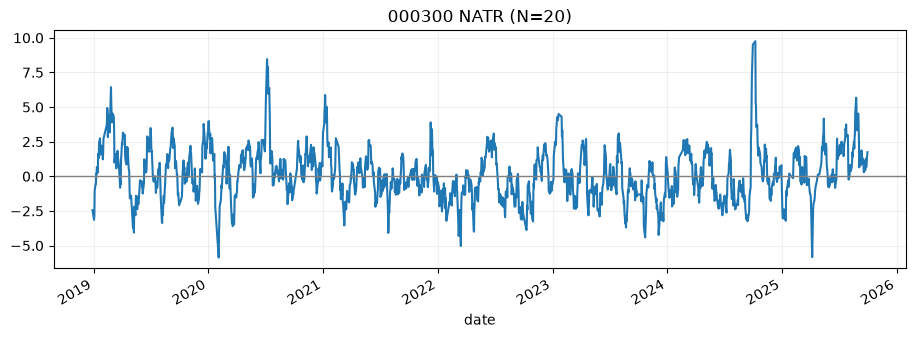

In [43]:
# 12. 画出本指数NATR（看看它在0上下如何变化）
demo.loc[BASE_2019:END, 'NATR'].plot(
    figsize=(11, 3.5),
    title=f'{DEMO_CODE} NATR (N={N})'
)
plt.axhline(0, color='gray', linewidth=1)
plt.grid(alpha=.2); plt.show()

In [44]:
# 13. 把同一套ATR公式封装为一个小函数

def add_atr(d):
    d = d.copy()
    prev = d['close'].shift(1)
    d['TR'] = pd.concat([d.high-d.low,(d.high-prev).abs(),(d.low-prev).abs()],axis=1).max(axis=1)
    d['ATR'] = d['TR'].rolling(N,min_periods=N).mean()
    d['MC'] = d['close'].rolling(N,min_periods=N).mean()
    d['NATR'] = (d.close-d.MC)/d.ATR.replace(0,np.nan)
    # d.ATR.replace(0, np.nan)：将分母中的0替换为缺失值，避免除以0
    return d

In [45]:
# 14. 为所有可用指数计算ATR和NATR
features = {code:add_atr(d) for code,d in indexes.items()}
display(features[DEMO_CODE][['ATR','NATR']].tail())

,ATR,NATR
date,,
2025-09-24,74.3370,0.959287
2025-09-25,72.0610,1.280096
2025-09-26,71.2270,0.647795
2025-09-29,74.5040,1.494195
2025-09-30,71.3445,1.744374


## 第3章：复现第7—8页基础网格

研报第7页表1：中枢权重50%，NATR落入[1,2)时仓位40%，落入(-2,-1]时仓位60%，上下极限0%与100%。我们把这张表写成一个通用函数。

In [46]:
# 15. 定义NATR到目标仓位的映射（每档10个百分点）
def grid_weight(natr, center=0.5, up_gap=1.0, down_gap=1.0):
    x = np.asarray(natr, dtype=float)
    positive = np.minimum(5,np.floor(np.maximum(x,0)/up_gap))
    negative = np.minimum(5,np.floor(np.maximum(-x,0)/down_gap))
    weight = np.clip(center-0.10*positive+0.10*negative,0,1)
    return pd.Series(weight,index=natr.index)

In [47]:
# 16. 使用已知边界测试网格函数
example = pd.Series([-5,-3,-1,-0.5,0,0.5,1,3,5])
check = pd.DataFrame({'NATR':example,'目标仓位':grid_weight(example)})
display(check)
assert np.allclose(check['目标仓位'], [1,.8,.6,.5,.5,.5,.4,.2,0])

,NATR,目标仓位
0,-5.0,1.0
1,-3.0,0.8
2,-1.0,0.6
3,-0.5,0.5
4,0.0,0.5
5,0.5,0.5
6,1.0,0.4
7,3.0,0.2
8,5.0,0.0


In [48]:
# 17. 为六只指数生成基础网格目标仓位
for code,d in features.items():
    d['w_base'] = grid_weight(d['NATR'])
display(features[DEMO_CODE][['NATR','w_base']].tail())

,NATR,w_base
date,,
2025-09-24,0.959287,0.5
2025-09-25,1.280096,0.4
2025-09-26,0.647795,0.5
2025-09-29,1.494195,0.4
2025-09-30,1.744374,0.4


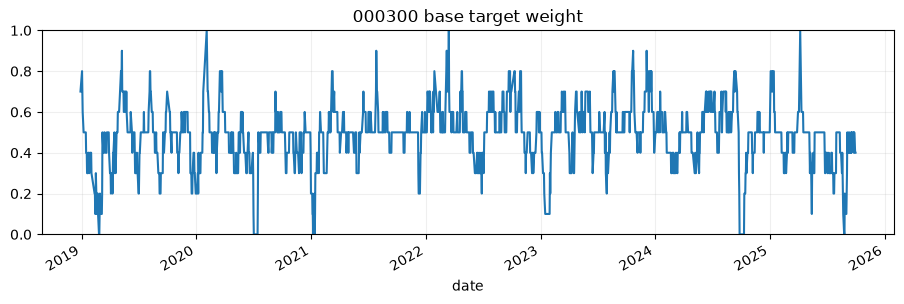

In [49]:
# 18. 画出基础网格仓位变化图
features[DEMO_CODE].loc[BASE_2019:END, 'w_base'].plot(
    figsize=(11, 3),
    title=f'{DEMO_CODE} base target weight'
)
plt.ylim(0,1); plt.grid(alpha=.2);plt.show()

## 第4章：只用指数模拟一次收益回测

**防未来函数的示范执行规则：** 第t日收盘计算目标仓位，第t+1日收盘假定完成交易，旧持仓赚到t+1日收益，新持仓从t+2日收盘收益开始生效。因此用于当天收盘收益的仓位是 `target.shift(2)`。此规则是教学假设，不代表原研报明确采用的交易执行方式。交易成本在模拟调仓日收取。

In [50]:
# 19. 定义指数策略的逐日收益计算
def index_backtest(d, weight_col, start='2019-01-02'):
    daily_r = d['close'].pct_change().fillna(0)
    # 当天收益率 = 当天收盘价/前一天收盘价-1， 第一行填0
    holding = d[weight_col].shift(2).fillna(0)
    # 当天的收益使用前两个交易日生成的目标仓位
    # 周一收盘产生的目标仓位，周二调仓，周三的收益对应周一的目标仓位
    trade_weight = d[weight_col].shift(1).fillna(0)
    # 交易费用采用周二的数据
    cost = trade_weight.diff().abs().fillna(trade_weight.abs())*FEE_BPS/10000
    # .diff()：当天目标仓位减去上一天目标仓位
    # .abs()：买入、卖出都按变动幅度计算成本
    # .fillna(trade_weight.abs())：第一行没有前值时，按从零仓位建仓计算
    # / 10000：将基点（bps）换成小数费率，1基点等于0.01%
    result = pd.DataFrame({'strategy':holding*daily_r-cost,'index':daily_r})
    # strategy 是“策略账户当天的收益率”：当天账户资产相对上一交易日收盘资产的变化比例，已经扣除代码中模拟的交易成本
    return result.loc[start:END]

In [51]:
# 20. 运行基础网格与指数买入持有对比
base_test = index_backtest(
    features[DEMO_CODE], 'w_base', start=START_2019
)

base_nav = (1 + base_test).cumprod() # 连续多天的账户净值需要累乘

# 在首个收益日之前补上净值为1的基点
base_nav.loc[BASE_2019] = 1.0
base_nav = base_nav.sort_index()

display(base_nav.head(3))
display(base_nav.tail(3))

,strategy,index
date,,
2018-12-28,1.000000,1.000000
2019-01-02,0.989076,0.986345
2019-01-03,0.987980,0.984784


,strategy,index
date,,
2025-09-26,1.193245,1.511318
2025-09-29,1.200588,1.534569
2025-09-30,1.203270,1.541425


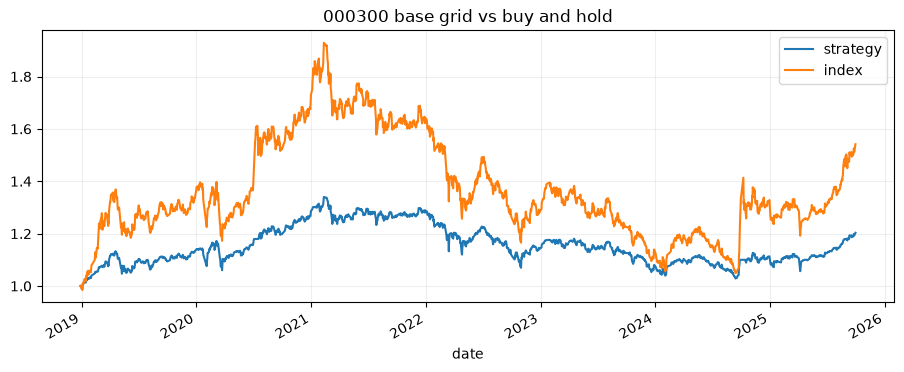

In [52]:
# 21. 画基础网格和指数买入持有的净值曲线
base_nav.plot(figsize=(11,4),title=f'{DEMO_CODE} base grid vs buy and hold')
plt.grid(alpha=.2);plt.show()

In [53]:
# 22. 定义回测常用绩效指标（最大回撤显示为正数）
def performance(daily_r):
    r = daily_r.fillna(0).astype(float)
    nav = (1+r).cumprod() # 复利，累乘收益率
    peaks = np.maximum.accumulate(np.r_[1.0,nav.to_numpy()])
    # nav.to_numpy()：将净值序列转为数组
    # np.r_[1.0, ...]：在最前面加入初始净值1
    # np.maximum.accumulate(...)：依次计算“截至当前的历史最高值”
    max_dd = np.max(1-np.r_[1.0,nav.to_numpy()]/peaks)
    # 最大回撤=1-当前净值/截止当前的历史最高净值
    vol = r.std()*np.sqrt(252)
    # r.std() 是每日收益率的样本标准差，衡量收益的波动程度
    # 乘以 √252，按一年252个交易日换算成 年化波动率
    return {'年化收益':nav.iloc[-1]**(252/len(r))-1,
            '最大回撤':max_dd,'年化波动率':vol,
            '夏普(无风险0)':r.mean()*252/vol if vol>0 else np.nan}

In [54]:
# 23. 查看基础网格和指数基准的绩效
base_stats = pd.DataFrame({name:performance(base_test[name]) for name in base_test}).T
shown = base_stats.copy()

for col in ["年化收益", "最大回撤", "年化波动率"]:
    shown[col] = shown[col].map(lambda x: f"{x:.2%}")

shown["夏普(无风险0)"] = shown["夏普(无风险0)"].map(
    lambda x: f"{x:.2f}"
)

display(shown)

,年化收益,最大回撤,年化波动率,夏普(无风险0)
strategy,2.89%,23.24%,9.58%,0.34
index,6.88%,45.60%,19.22%,0.44


## 第5章：复现第9—10页 ATR择时

第9页规定：ATR均线下降且价格均线上升为**看多**；ATR均线下降且价格均线下降为**看空**；ATR均线上升时**没有择时信号**。`signal=1`表示看多，`-1`表示看空，`0`表示无信号。

第9页表2还给出了4种仓位改进方法。下面逐格实现。

In [55]:
# 24. 计算ATR与指数价格的N1日均线
def add_timing_ma(d):
    d['MATR'] = d['ATR'].rolling(N1,min_periods=N1).mean()
    d['MC1'] = d['close'].rolling(N1,min_periods=N1).mean()
    return d
for d in features.values():
    add_timing_ma(d)

In [ ]:
# 25. 按第9页定义看多(1)、看空(-1)、无信号(0)
for d in features.values():
    atr_down = d['MATR'] < d['MATR'].shift(1) 
    # 今天的ATR均线 < 上一个交易日的ATR均线，结果是一整列 True/False
    price_up = d['MC1'] > d['MC1'].shift(1)
    # 判断每天的价格均线是否上升、是否下降
    price_down = d['MC1'] < d['MC1'].shift(1)
    d['timing'] = np.select([atr_down & price_up,atr_down & price_down],[1,-1],0)
    # ATR均线下降，同时价格均线上升，则写入timing=1，看多
    # ATR均线下降，同时价格均线下降，则写入timing=-1，看空
    # 其他情况，写入timing=0
# display(features[DEMO_CODE][['MATR','MC1','timing']].tail())
# 查看完整研究区间内三种信号各有多少天：
timing_sample = features[DEMO_CODE].loc[START_2019:END, 'timing']
display(timing_sample.value_counts().reindex([-1, 0, 1], fill_value=0))

timing
-1    422
 0    721
 1    496
Name: count, dtype: int64

In [ ]:
# 26. 实现择时策略1：看多时减仓更慢、加仓更快；看空时反过来
for d in features.values():
    up = np.where(d.timing==1,2.0,np.where(d.timing==-1,0.5,1.0))
    # np.where(条件, 成立时取值, 不成立时取值) 按每天的信号选择网格间距 
    # 看多时，timing=1，此时令up=2.0，令down=0.5，增大减仓间距，减小加仓间距，更难减仓，更容易加仓
    down = np.where(d.timing==1,0.5,np.where(d.timing==-1,2.0,1.0))
    # 看空时，timing=-1，此时令up=0.5，令down=2.0，减小减仓间距，增大加仓间距，更容易减仓，更难加仓
    d['w_t1'] = grid_weight(d.NATR,up_gap=up,down_gap=down)
    # 用当天的NATR和调整后的间距，计算目标仓位，写入原表的 w_t1 列，供后续回测使用

In [59]:
# 27. 策略2：看多仓位中枢60%，看空40%
for d in features.values():
    center = np.where(d.timing==1,0.6,np.where(d.timing==-1,0.4,0.5))
    d['w_t2'] = grid_weight(d.NATR,center=center)

In [ ]:
# 28. 策略3：看多仓位不低于50%，看空不高于50%
for d in features.values():
    d['w_t3'] = np.where(d.timing==1,np.maximum(d.w_base,0.5),
                         np.where(d.timing==-1,np.minimum(d.w_base,0.5),d.w_base))
    d.loc[d.NATR.isna(),'w_t3'] = np.nan
    # 找出NATR缺失的日期，把这些日期的策略3仓位也设为缺失值
    # 没有有效NATR，就不应生成有效的策略3仓位

In [ ]:
# 29. 策略4：看多不能比上期减仓，看空不能比上期加仓
def limit_vs_last(base, timing):
    # base：每天的基础网格仓位
    # timing：每天的择时信号，`1`看多、`-1`看空、`0`无信号
    result, last = [], np.nan
    # result 用来保存调整后的仓位；`last` 记录上一次有效的策略4仓位，初始没有值
    for weight, direction in zip(base,timing):
        # zip 把两个序列按位置配对，每次取出同一天的基础仓位和择时信号
        if pd.isna(weight): result.append(np.nan);continue
        # 当天基础仓位缺失，就记录 NaN，跳过当天
        if direction==1 and pd.notna(last): weight=max(weight,last)
        # 看多且已有上期仓位时，取“基础仓位”和“上期策略4仓位”的较大值，防止减仓
        if direction==-1 and pd.notna(last): weight=min(weight,last)
        # 看空时取较小值，防止加仓
        result.append(weight);last=weight
    return result

In [62]:
# 30. 把策略4应用到所有指数
for d in features.values():
    d['w_t4'] = limit_vs_last(d['w_base'],d['timing'])
display(features[DEMO_CODE][['w_base','w_t1','w_t2','w_t3','w_t4']].tail())

,w_base,w_t1,w_t2,w_t3,w_t4
date,,,,,
2025-09-24,0.5,0.5,0.5,0.5,0.5
2025-09-25,0.4,0.4,0.4,0.4,0.4
2025-09-26,0.5,0.5,0.5,0.5,0.5
2025-09-29,0.4,0.4,0.4,0.4,0.4
2025-09-30,0.4,0.4,0.4,0.4,0.4


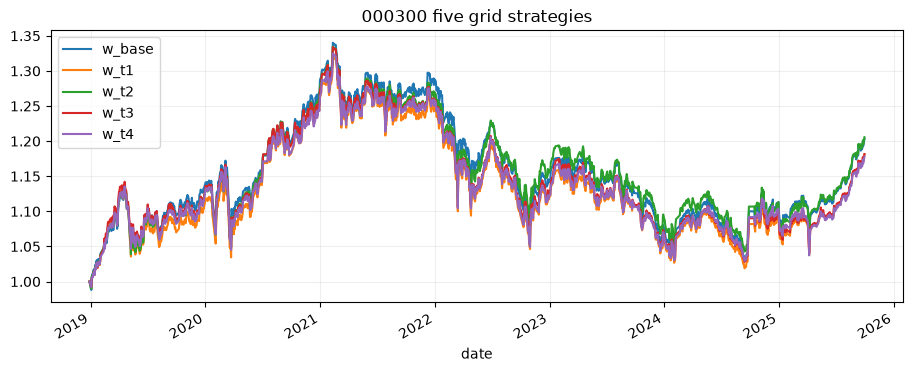

In [ ]:
# 31. 把基础网格和四种择时策略放在同一张净值图里
methods = ['w_base', 'w_t1', 'w_t2', 'w_t3', 'w_t4']

all_nav = pd.DataFrame({
    m: (
        1 + index_backtest(
            features[DEMO_CODE], m, start=START_2019
        )['strategy']  # 用示例指数的数据，按策略 m 的目标仓位回测，从 START_2019 开始返回每日收益
    ).cumprod() # 每日收益累乘，得到累计净值
    for m in methods
})
# {m: ... for m in methods}是字典推导式：以策略名称为键，以对应净值序列为值

# 补上2019年样本的净值基点
all_nav.loc[BASE_2019] = 1.0
all_nav = all_nav.sort_index()

all_nav.plot(
    figsize=(11, 4),
    title=f'{DEMO_CODE} five grid strategies'
)
plt.grid(alpha=.2)
plt.show()

In [64]:
# 32. 计算五种策略的绩效对比
stats = pd.DataFrame({m:performance(index_backtest(features[DEMO_CODE],m)['strategy']) for m in methods}).T
display(stats.round(4))

,年化收益,最大回撤,年化波动率,夏普(无风险0)
w_base,0.0289,0.2324,0.0958,0.3449
w_t1,0.0259,0.2284,0.0956,0.3156
w_t2,0.0292,0.2188,0.0958,0.3481
w_t3,0.0260,0.2293,0.0948,0.3180
w_t4,0.0255,0.2228,0.0951,0.3127


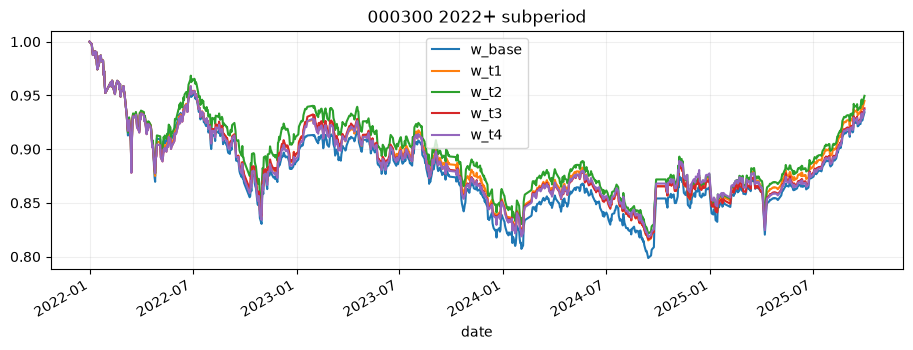

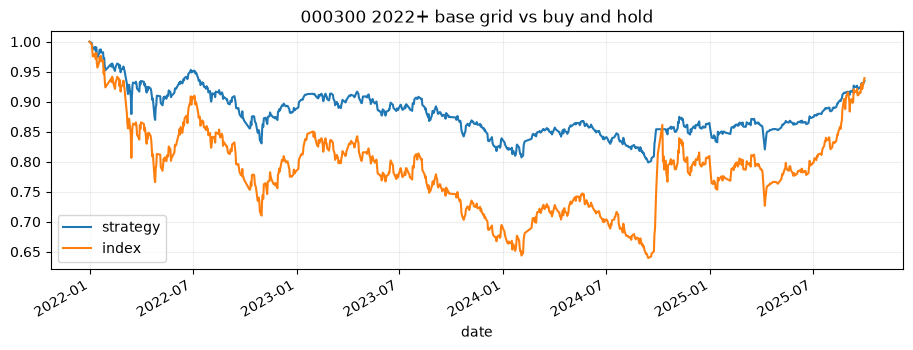

,strategy,index
date,,
2021-12-31,1.000000,1.000000
2022-01-04,0.997713,0.995425
2022-01-05,0.992676,0.985376


,strategy,index
date,,
2025-09-26,0.926498,0.920994
2025-09-29,0.932199,0.935163
2025-09-30,0.934282,0.939341


In [ ]:
# 33. 再看2022年初至2025年9月30日的子样本

# 第一张图：五种策略对比
from_2022 = pd.DataFrame({
    m: (
        1 + index_backtest(
            features[DEMO_CODE], m, start=START_2022
        )['strategy']
    ).cumprod()
    for m in methods
})

from_2022.loc[BASE_2022] = 1.0
from_2022 = from_2022.sort_index()

from_2022.plot(
    figsize=(11, 3.5),
    title=f'{DEMO_CODE} 2022+ subperiod'
)
plt.grid(alpha=.2)
plt.show()

# 第二张图：基础网格与指数买入持有对比
base_test_2022 = index_backtest(
    features[DEMO_CODE], 'w_base', start=START_2022
) 
# 使用示例指数的数据，按基础网格仓位 w_base 回测，从 2022-01-04 开始统计每日收益
# 返回两列：strategy：基础网格策略的每日收益率；index：指数买入持有的每日收益率
base_nav_2022 = (1 + base_test_2022).cumprod()
# 对两列分别累乘，将每日收益率转成累计净值
base_nav_2022.loc[BASE_2022] = 1.0
# 在 2021-12-31 增加一行，将两列净值都设为1，作为曲线的起始点
base_nav_2022 = base_nav_2022.sort_index()
# 按日期排序，把刚补入的2021年12月31日放到最前面

base_nav_2022.plot(
    figsize=(11, 3.5),
    title=f'{DEMO_CODE} 2022+ base grid vs buy and hold'
)
plt.grid(alpha=.2) # 添加透明度为0.2的浅色网格线
plt.show()
# 图中可以看到，strategy和index两条曲线低于1，说明它们相对2021年12月31日的起始资产仍然亏损
# 大部分时间strategy>index，但是最后一天，index已经略高于strategy
# 这说明：strategy在此前下跌阶段亏得较少，但在后来的上涨中，index逐渐追上，最终略微反超
display(base_nav_2022.head(3))
display(base_nav_2022.tail(3))

## 第6章：保存本Notebook成果，供ETF组合Notebook读取

这里会导出每只指数的 `date / close / ATR / NATR / timing / w_base / w_t1 ... w_t4`，所以第二个Notebook不必重新算一遍策略。

In [66]:
# 34. 导出各指数的中间结果CSV（第二个Notebook需要）
for code,d in features.items():
    d.to_csv(FEATURE_DIR/f'{code}.csv',encoding='utf-8-sig',index_label='date')
print(f'已导出 {len(features)} 个指数信号文件到:',FEATURE_DIR)

已导出 6 个指数信号文件到: d:\Project\Quant-ETF\outputs\features


In [67]:
# 35. 导出沪深300/示例指数的策略净值和统计结果
base_nav.to_csv(OUTPUT/f'{DEMO_CODE}_base_nav.csv',encoding='utf-8-sig')
stats.to_csv(OUTPUT/f'{DEMO_CODE}_timing_metrics.csv',encoding='utf-8-sig')
print('已保存基础净值和择时策略指标')

已保存基础净值和择时策略指标


### 本Notebook验收标准

- [ ] ATR/NATR曲线可以画出来，并能理解第6页公式。
- [ ] 网格仓位边界测试通过（NATR=1对应40%；NATR=-1对应60%）。
- [ ] 基础网格与指数基准净值曲线生成。
- [ ] 五种方法净值与绩效结果可见。
- [ ] `outputs/index_signals/` 中有6个CSV（如果少于6个，请先补齐原始指数数据）。

**之后再打开 `02_六宽基ETF分红复权与组合.ipynb`。**